# 02 · Reversible training: which integrator works?

> **Brief, part 2.** *Train again with Reversibility (report which variant worked for you, mid-point, euler, etc).*

The lesson's §16 rule, written for every variant at once. Here $s_k$ is the residual stream entering layer $k$, and $f_k$ is the whole block (attention, then MLP) minus its input:

$$ s_{k+1} \;=\; \alpha\, s_{k-1} \;+\; \beta\, s_k \;+\; \gamma\, f_k(s_k) \qquad\Longleftrightarrow\qquad s_{k-1} \;=\; \frac{s_{k+1} - \beta\, s_k - \gamma\, f_k(s_k)}{\alpha} $$

| integrator | α | β | γ | source |
|---|:-:|:-:|:-:|---|
| **midpoint** | 1 | 0 | 2h | Gal et al. Eq. 4, the lesson's rule |
| **blend** | a | 1−a | h | Gal et al. Eq. 15. Lightning LM runs a = 0.5, h = 0.25 |
| **leapfrog** | −1 | 2 | h² | Gal et al. Eq. 6 |

**Where "Euler" comes in.** Plain forward Euler, $s_{k+1} = s_k + h f_k(s_k)$, is the *standard* residual block. Lesson §16 shows it cannot be reversed. A two-step rule, though, needs two starting states, and Euler is how the Lightning LM integrator makes the second one: `bootstrap = euler` sets $s_1 = s_0 + h f_0(s_0)$. The alternative, `no_kick`, sets $s_1 = s_0$. Gal et al. §3.2 also show that the blend rule *"behaves like forward Euler in expectation"*.

So this notebook tests every integrator × {Euler start, no-kick start}, plus the integrator library's own defaults (a = 0.95, h = 0.05, no-kick), which Lightning LM warns are **not** what it trains with.

In [1]:
# --- setup: works on Modal, on Colab (clones the repo) and locally -------------------------
import os, sys, json, math
from pathlib import Path
if 'google.colab' in sys.modules and not Path('/content/era-v5-s13-reversibility').exists():
    !git clone -q https://github.com/sourav-dhar/era-v5-s13-reversibility /content/era-v5-s13-reversibility
    !pip -q install tiktoken datasets
    os.environ.setdefault('S13_PROFILE', 'colab')
    os.chdir('/content/era-v5-s13-reversibility/notebooks')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, matplotlib.pyplot as plt
from s13 import store, viz, probe
from s13.profiles import P
from s13.train import run, gpu_name, device, DEFAULTS
from s13.data import prepare, data_dir
viz.style()
GiB = 2**30
PROF, CFG = store.profile(), P()
B0 = dict(CFG['base'])
CUDA = torch.cuda.is_available()
print(f'profile = {PROF} | device = {gpu_name(device())} | torch {torch.__version__}')
print('data   :', prepare(data_dir(), **CFG['data']))

profile = full | device = NVIDIA A100-SXM4-40GB | torch 2.8.0+cu128


/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


data   : {'repo': 'HuggingFaceFW/fineweb-edu', 'subset': 'sample-10BT', 'tokenizer': 'gpt2', 'eot': 50256, 'val': {'tokens': 2000000, 'docs': 1851}, 'train': {'tokens': 52000000, 'docs': 49409}}


In [2]:
from s13 import report
from s13.reversible import RevCfg
FIXED_B = store.load('fixed_batch')['batch']
TOK = CFG['tokens']
print('fixed batch:', FIXED_B, 'sequences | tokens per run:', f'{TOK:,}')

fixed batch: 32 sequences | tokens per run: 50,000,000


## 1 · Stability, before any training

Set $f = 0$ and each rule becomes a linear recurrence with characteristic equation $z^2 = \beta z + \alpha$. The forward pass multiplies errors by up to $\max|z|$ per layer. The **reconstruction runs the recurrence backward**, so it multiplies them by $\max|1/z|$.

Gal et al. require $|\alpha| = 1$ for stability. The table shows why, from the backward side: once $|\alpha| < 1$, rebuilding the states amplifies rounding error geometrically.

In [3]:
rows = []
for name, a_, b_ in [('midpoint', 1, 0), ('blend a=0.5 (Lightning)', 0.5, 0.5), ('blend a=0.95 (library default)', 0.95, 0.05), ('leapfrog', -1, 2)]:
    r, fwd, bwd = report.char_roots(a_, b_)
    rows.append((name, np.round(r.real, 3).tolist(), fwd, bwd, bwd ** 11))
print(f"{'rule':<32}{'roots':<18}{'fwd |z|':>9}{'bwd |1/z|':>11}{'bwd x 11 layers':>17}")
for n, r, f_, b_, b11 in rows:
    print(f'{n:<32}{str(r):<18}{f_:>9.3f}{b_:>11.3f}{b11:>17.1f}')

rule                            roots               fwd |z|  bwd |1/z|  bwd x 11 layers
midpoint                        [-1.0, 1.0]           1.000      1.000              1.0
blend a=0.5 (Lightning)         [1.0, -0.5]           1.000      2.000           2048.0
blend a=0.95 (library default)  [1.0, -0.95]          1.000      1.053              1.8
leapfrog                        [1.0, 1.0]            1.000      1.000              1.0


Read the last column as a prediction. Rebuilding 11 layers with **blend a = 0.5** should multiply rounding error by about **2¹¹ ≈ 2,000×**. Midpoint and leapfrog should not amplify it at all, though leapfrog's double root at 1 allows slow linear growth. Notebook 04 measures this on the trained models.

## 2 · Exactness: is the reversible gradient the real gradient?

The custom backward stores two states and rebuilds the rest. In float64 it must return the same gradient as ordinary autograd run through the same rule. `tests/test_reversible.py` checks this for every variant, to 1e-9.

Below, the same check on this GPU at full size in fp32, followed by what bf16 autocast does to it.

In [4]:
from s13.train import build
from s13.reversible import integrate
torch.manual_seed(0)
dev = device()
for rc in [RevCfg('midpoint', 0.5), RevCfg('blend', 0.25, 0.5), RevCfg('leapfrog', 1.0)]:
    cfg = dict(DEFAULTS, **B0, mode='rev', integrator=rc.integrator, h=rc.h, a=rc.a)
    m = build(cfg, dev)
    idx = torch.randint(0, 50257, (2, B0.get('seq', 1024)), device=dev)
    fid = probe.grad_fidelity(m, idx, idx)
    worst = min(fid, key=lambda r: r['cos'])
    print(f"{rc.label():<34} fp32+bf16-autocast: worst-layer cosine {worst['cos']:.8f}, worst rel. error {max(r['rel_err'] for r in fid):.2e}")
    del m

midpoint h=0.5, boot=euler         fp32+bf16-autocast: worst-layer cosine 0.99972234, worst rel. error 2.36e-02


blend a=0.5 h=0.25, boot=euler     fp32+bf16-autocast: worst-layer cosine 0.97165468, worst rel. error 2.37e-01


leapfrog h=1, boot=euler           fp32+bf16-autocast: worst-layer cosine 0.99806421, worst rel. error 6.23e-02


## 3 · Train every variant on the baseline's tokens and batch

Same 50M tokens, same order, same batch, same optimizer as notebook 01. Each run saves its weights for the drift study in notebook 04.

In [5]:
runs = {}
for name, integ, h, a, boot in CFG['variants']:
    cfg = dict(B0, name=f'rev-{name}', mode='rev', integrator=integ, h=h, a=a, bootstrap=boot,
               batch=FIXED_B, tokens=TOK, save=str(store.ckpt_dir() / f'rev-{name}.pt'))
    runs[name] = store.cached(f'run_rev-{name}', lambda cfg=cfg: run(cfg))
baseline, ckpt = store.load('run_baseline'), store.load('run_ckpt')
report.table([baseline, ckpt] + list(runs.values()))

[cache] run_rev-midpoint-euler: loaded from full/run_rev-midpoint-euler.json
[cache] run_rev-midpoint-nokick: loaded from full/run_rev-midpoint-nokick.json
[cache] run_rev-blend-euler: loaded from full/run_rev-blend-euler.json
[cache] run_rev-blend-nokick: loaded from full/run_rev-blend-nokick.json
[cache] run_rev-blend-libdefault: loaded from full/run_rev-blend-libdefault.json
[cache] run_rev-leapfrog-euler: loaded from full/run_rev-leapfrog-euler.json


[cache] run_rev-leapfrog-nokick: loaded from full/run_rev-leapfrog-nokick.json


,what,batch (seq),tokens/step,steps,final val loss,final train loss,tokens/s,peak mem (GiB),wall (s),cost ($)
run,,,,,,,,,,
baseline,standard (stores activations),32,32768,1525,4.4480,4.3943,199981,24.96,265,0.155
ckpt,activation checkpointing,32,32768,1525,4.4486,4.3938,170371,19.56,308,0.180
rev-midpoint-euler,"midpoint h=0.5, Euler start",32,32768,1525,4.5182,4.4662,162835,19.05,322,0.188
rev-midpoint-nokick,"midpoint h=0.5, no-kick start",32,32768,1525,4.5064,4.4520,162562,19.05,322,0.188
rev-blend-euler,"blend a=0.5, h=0.25, Euler start",32,32768,1525,4.8957,4.8380,157350,19.05,333,0.195
rev-blend-nokick,"blend a=0.5, h=0.25, no-kick start",32,32768,1525,4.8761,4.8184,156626,19.05,334,0.195
rev-blend-libdefault,"blend a=0.95, h=0.05, no-kick start",32,32768,1525,4.9753,4.9103,156522,19.05,335,0.196
rev-leapfrog-euler,"leapfrog h=1, Euler start",32,32768,1525,4.5299,4.4748,157238,19.05,333,0.195
rev-leapfrog-nokick,"leapfrog h=1, no-kick start",32,32768,1525,4.5427,4.4864,156650,19.05,334,0.195


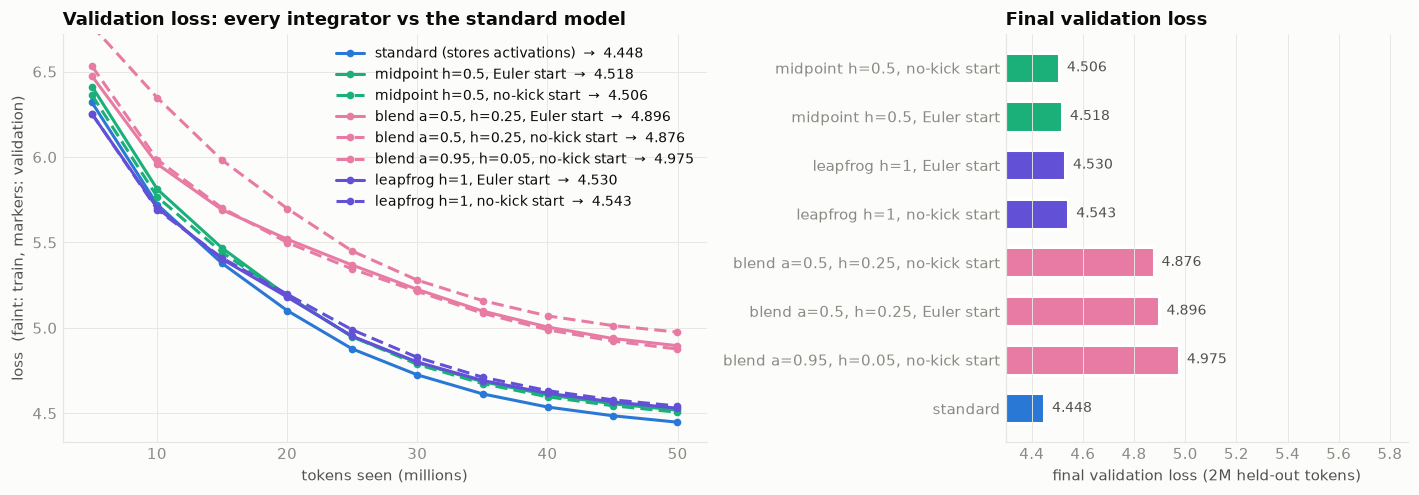

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.6, 1]})
ok = [r for r in runs.values() if not r['diverged']]
report.curves([baseline] + ok, 'Validation loss: every integrator vs the standard model', ax=axes[0], show_train=False)
axes[0].set_ylim(top=min(7.5, baseline['evals']['val'][0] + 0.4))
srt = sorted(ok, key=lambda r: r['final_val'])
report.hbars(axes[1], [report.label(r) for r in srt] + ['standard'],
             [r['final_val'] for r in srt] + [baseline['final_val']],
             [viz.rev_color(r['cfg']) for r in srt] + [viz.COLOR['standard']], fmt='{:.3f}', xlabel='final validation loss (2M held-out tokens)')
lo = min(r['final_val'] for r in srt + [baseline]); axes[1].set_xlim(lo - 0.15, None)
axes[1].set_title('Final validation loss')
fig.tight_layout(); viz.save(fig, '02_variants'); plt.show()

In [7]:
print(f"{'variant':<40}{'Δ val vs std':>13}{'speed vs std':>14}{'peak mem':>11}{'vs std':>8}")
for r in [ckpt] + list(runs.values()):
    dv = r['final_val'] - baseline['final_val']
    print(f"{report.label(r):<40}{dv:>+13.4f}{r['tok_per_s']/baseline['tok_per_s']:>13.2f}x"
          f"{r['peak_mem_bytes']/GiB:>9.2f}Gi{r['peak_mem_bytes']/baseline['peak_mem_bytes']:>7.2f}x")
winner = min(ok, key=lambda r: r['final_val'])
store.save('winner', {k: winner['cfg'][k] for k in ('integrator', 'h', 'a', 'bootstrap', 'name')} | {'final_val': winner['final_val']})
print('\nwinner:', report.label(winner), f"val {winner['final_val']:.4f}")

variant                                  Δ val vs std  speed vs std   peak mem  vs std
activation checkpointing                      +0.0006         0.85x    19.56Gi   0.78x
midpoint h=0.5, Euler start                   +0.0702         0.81x    19.05Gi   0.76x
midpoint h=0.5, no-kick start                 +0.0584         0.81x    19.05Gi   0.76x
blend a=0.5, h=0.25, Euler start              +0.4477         0.79x    19.05Gi   0.76x
blend a=0.5, h=0.25, no-kick start            +0.4281         0.78x    19.05Gi   0.76x
blend a=0.95, h=0.05, no-kick start           +0.5273         0.78x    19.05Gi   0.76x
leapfrog h=1, Euler start                     +0.0819         0.79x    19.05Gi   0.76x
leapfrog h=1, no-kick start                   +0.0947         0.78x    19.05Gi   0.76x

winner: midpoint h=0.5, no-kick start val 4.5064


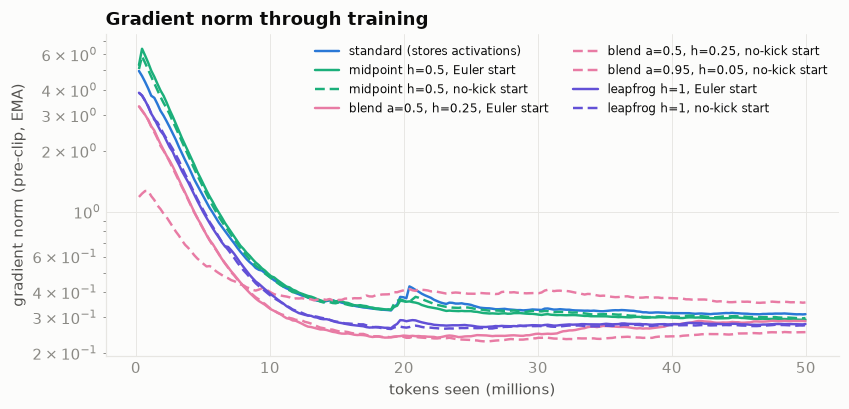

In [8]:
fig, ax = plt.subplots(figsize=(8.6, 3.8))
for r in [baseline] + ok:
    t = np.array(r['curve']['tokens']) / 1e6
    ax.plot(t, viz.ema(r['curve']['gnorm'], 0.9), color=viz.rev_color(r['cfg']),
            ls=viz.DASH.get(r['cfg'].get('bootstrap'), '-') if r['cfg']['mode'] == 'rev' else '-', lw=1.6, label=report.label(r))
ax.set_yscale('log'); ax.set_xlabel('tokens seen (millions)'); ax.set_ylabel('gradient norm (pre-clip, EMA)')
ax.set_title('Gradient norm through training'); ax.legend(fontsize=8, ncol=2)
viz.save(fig, '02_gradnorm'); plt.show()

In [9]:
for r in [baseline, winner]:
    print(f'== {report.label(r)}')
    for s in r.get('samples', []):
        print('  —', s.replace('\n', ' '))

== standard (stores activations)
  — The most important thing about learning is to be able to be at a very small scale, with a relatively large scale of time, making it easier to use. - To create a way of learning from a different perspective. - For the first time, it is important
  — In the year 1850, we have spent the last six months to work on a similar study. The project has been supported by one of the most important aspects of the research. The project was developed to learn the different types of the project and to create research for the
== midpoint h=0.5, no-kick start
  — The most important thing about learning is to learn. Here are some important tips for learning how to learn about learning from teaching and learning in classrooms. - Teaching is a complex process that helps students learn from learning. - Learning is a way to incorporate learning into a learning
  — In the year 1850, the new study from the College of Public Health found that one could identify the two speci

## 4 · Ablation: is it the rule, or the step size?

The blend runs lost by more than 0.4. Blend has two differences from midpoint, though. It averages the two previous states, and its weight on the block is γ = h = 0.25, a quarter of midpoint's γ = 2h = 1. Each block therefore contributes four times less to the residual stream per layer.

The three runs below separate the two effects, all with the no-kick start:

* **blend with h = 1**, so γ = 1, the same weight as the midpoint winner,
* **midpoint with h = 0.25** (γ = 0.5) and **h = 1** (γ = 2), to see how midpoint itself responds to its step.

These runs are not eligible to be the "winner". Notebook 03 was planned from the grid above.

In [10]:
abl = {}
for name, integ, h, a, boot in CFG.get('ablation', []):
    cfg = dict(B0, name=f'rev-{name}', mode='rev', integrator=integ, h=h, a=a, bootstrap=boot, batch=FIXED_B, tokens=TOK)
    abl[name] = store.cached(f'run_rev-{name}', lambda cfg=cfg: run(cfg))
gamma = lambda c: 2 * c['h'] if c['integrator'] == 'midpoint' else (c['h'] if c['integrator'] == 'blend' else c['h'] ** 2)
pts = [r for r in list(runs.values()) + list(abl.values()) if not r['diverged'] and r['cfg']['bootstrap'] == 'none' and r['cfg']['integrator'] in ('midpoint', 'blend')]
print(f"{'run':<26}{'integrator':<11}{'a':>6}{'h':>6}{'γ (weight on f)':>17}{'val':>9}{'Δ vs std':>10}")
for r in sorted(pts, key=lambda r: (r['cfg']['integrator'], gamma(r['cfg']))):
    c = r['cfg']
    print(f"{c['name']:<26}{c['integrator']:<11}{c['a'] if c['integrator']=='blend' else 1:>6}{c['h']:>6}{gamma(c):>17.2f}{r['final_val']:>9.4f}{r['final_val']-baseline['final_val']:>+10.4f}")

[cache] run_rev-abl-blend-h1: loaded from full/run_rev-abl-blend-h1.json
[cache] run_rev-abl-midpoint-h0.25: loaded from full/run_rev-abl-midpoint-h0.25.json
[cache] run_rev-abl-midpoint-h1: loaded from full/run_rev-abl-midpoint-h1.json
run                       integrator      a     h  γ (weight on f)      val  Δ vs std
rev-blend-libdefault      blend        0.95  0.05             0.05   4.9753   +0.5273
rev-blend-nokick          blend         0.5  0.25             0.25   4.8761   +0.4281
rev-abl-blend-h1          blend         0.5   1.0             1.00   6.0454   +1.5974
rev-abl-midpoint-h0.25    midpoint        1  0.25             0.50   4.4928   +0.0449
rev-midpoint-nokick       midpoint        1   0.5             1.00   4.5064   +0.0584
rev-abl-midpoint-h1       midpoint        1   1.0             2.00   4.5261   +0.0781


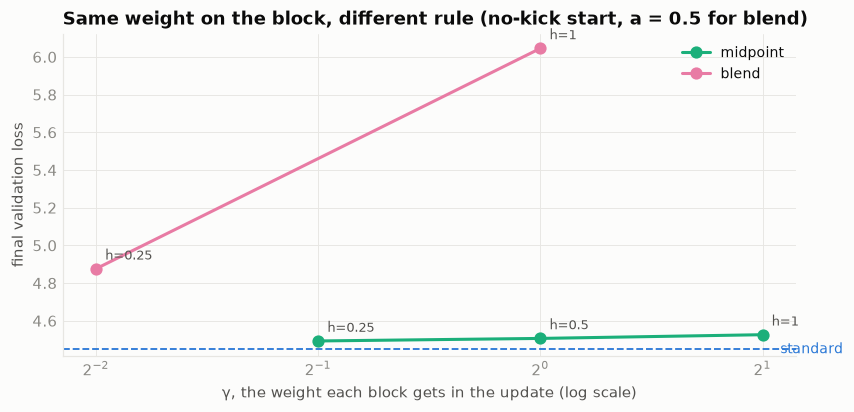

In [11]:
if pts:
    fig, ax = plt.subplots(figsize=(8.6, 3.8))
    for integ in ('midpoint', 'blend'):
        q = sorted([r for r in pts if r['cfg']['integrator'] == integ and (integ == 'midpoint' or r['cfg']['a'] == 0.5)],
                   key=lambda r: gamma(r['cfg']))
        ax.plot([gamma(r['cfg']) for r in q], [r['final_val'] for r in q], color=viz.COLOR[integ], marker='o', ms=7, label=integ)
        for r in q:
            ax.annotate(f"h={r['cfg']['h']:g}", (gamma(r['cfg']), r['final_val']), xytext=(6, 6), textcoords='offset points', fontsize=8.5, color=viz.INK2)
    ax.axhline(baseline['final_val'], color=viz.COLOR['standard'], lw=1.2, ls='--'); ax.text(ax.get_xlim()[1], baseline['final_val'], ' standard', va='center', color=viz.COLOR['standard'], fontsize=9)
    ax.set_xscale('log', base=2); ax.set_xlabel('γ, the weight each block gets in the update (log scale)'); ax.set_ylabel('final validation loss')
    ax.set_title('Same weight on the block, different rule (no-kick start, a = 0.5 for blend)'); ax.legend()
    viz.save(fig, '02_step_ablation'); plt.show()